# Chapitre 6 - Cours 4 : Agents et mémoire

Le RAG donne au modèle un outil : un retriever. Les **agents** généralisent l'idée : le modèle
dispose d'un **inventaire d'outils**, **planifie** une suite d'actions, observe les résultats
et se corrige. Ce notebook couvre les sections *Agents* (*Agent Overview*, *Tools*,
*Planning*, *Agent Failure Modes and Evaluation*) et *Memory*. L'auteure prévient que cette
partie du livre est plus expérimentale : le domaine évolue vite. Nous construisons tout à la
main avec Qwen2.5-0.5B-Instruct, qui gère nativement l'appel de fonctions en JSON.

Plan :

1. qu'est-ce qu'un agent ? environnement, actions, erreurs composées ;
2. les outils : inventaire, catégories, lecture et écriture ;
3. l'appel de fonctions en JSON avec Qwen ;
4. la planification : générer, valider, exécuter ;
5. la boucle ReAct ;
6. réflexion et correction d'erreurs ;
7. modes d'échec, évaluation et choix des outils ;
8. la mémoire : court terme, long terme, stratégies d'éviction.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import json
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 110)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
tok, _ = llm.load(llm.SMALL)
ntok = lambda t: len(tok(t)["input_ids"])  # noqa: E731

## 1. Qu'est-ce qu'un agent ? (section *Agent Overview*)

Suivant Russell et Norvig, un **agent** est tout ce qui **perçoit** son environnement et **agit**
sur lui. Il est donc caractérisé par son **environnement** (un jeu, Internet, un terminal, une
cuisine) et par l'ensemble des **actions** qu'il peut effectuer, étendu par ses **outils**. Les
deux sont liés : l'environnement détermine les outils possibles, et l'inventaire d'outils
restreint les environnements accessibles. Dans un agent à base de modèle de fondation, le
modèle est le **cerveau** : il reçoit la tâche et les retours de l'environnement, planifie les
actions et décide si la tâche est accomplie. Un RAG est un agent dont l'unique outil est un
retriever ; un RAG tabulaire en a deux (générer du SQL, l'exécuter).

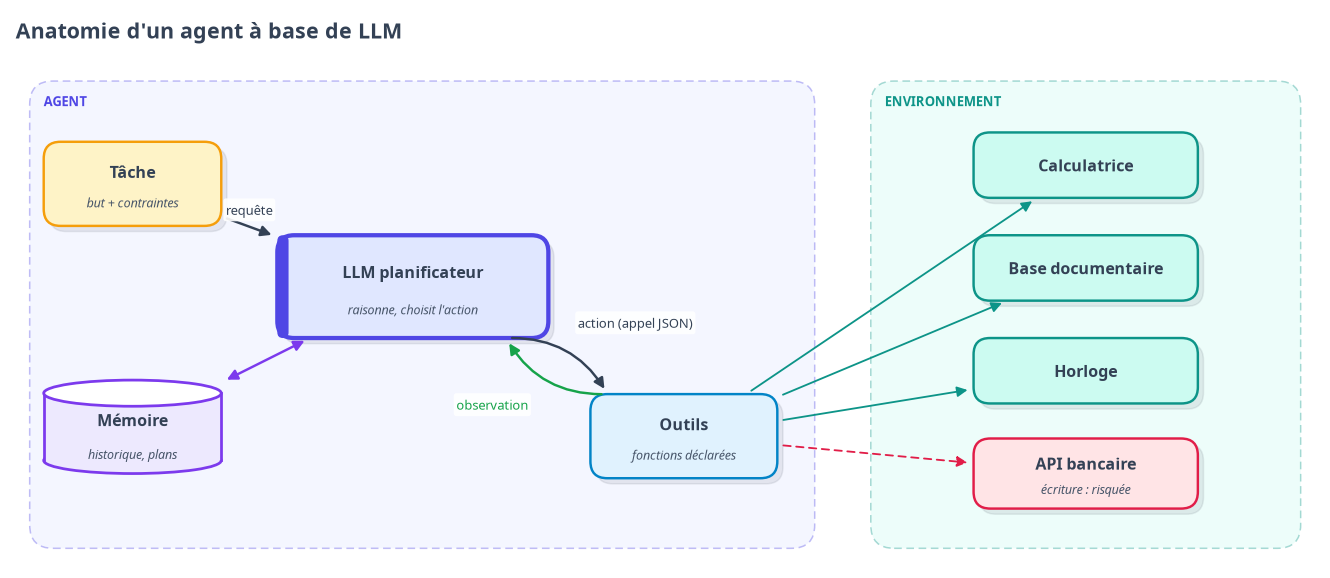

In [2]:
d = Diagram(14, 5.4, title="Anatomie d'un agent à base de LLM")
d.group(0.2, 0.2, 8.6, 5.2, "agent", color=INDIGO)
d.group(9.2, 0.2, 13.8, 5.2, "environnement", color=TEAL)
d.box("user", 1.3, 4.1, "Tâche", sub="but + contraintes", color=AMBER, w=1.9)
d.box("llm", 4.3, 3.0, "LLM planificateur", sub="raisonne, choisit l'action", color=INDIGO, kind="model", w=2.9, h=1.1)
d.box("mem", 1.3, 1.5, "Mémoire", sub="historique, plans", color=VIOLET, kind="db", w=1.9, h=1.0)
d.box("tools", 7.2, 1.4, "Outils", sub="fonctions déclarées", color=SKY, w=2.0)
d.box("calc", 11.5, 4.3, "Calculatrice", color=TEAL, w=2.4, h=0.7)
d.box("corpus", 11.5, 3.2, "Base documentaire", color=TEAL, w=2.4, h=0.7)
d.box("date", 11.5, 2.1, "Horloge", color=TEAL, w=2.4, h=0.7)
d.box("bank", 11.5, 1.0, "API bancaire", sub="écriture : risquée", color=ROSE, w=2.4, h=0.75)
d.arrow("user", "llm", "requête")
d.arrow("llm", "tools", "action (appel JSON)", rad=-0.3, label_offset=(0.75, 0.3))
d.arrow("mem", "llm", both=True, color=VIOLET)
for t_ in ["calc", "corpus", "date"]:
    d.arrow("tools", t_, color=TEAL, lw=1.2)
d.arrow("tools", "bank", color=ROSE, style="dashed", lw=1.2)
d.arrow("tools", "llm", "observation", rad=-0.3, color=GREEN, label_offset=(-0.6, -0.25))
d.show()

**Pourquoi les agents exigent des modèles plus forts.** Une tâche agentique enchaîne de
nombreuses étapes ; si chacune réussit avec une probabilité $p$ (indépendamment), la tâche
entière réussit avec probabilité $p^n$. Le livre donne l'exemple : 95 % par étape, c'est 60 %
sur 10 étapes et 0,6 % sur 100. Ajoutons que des **enjeux plus élevés** (actions réelles)
rendent chaque erreur plus coûteuse.

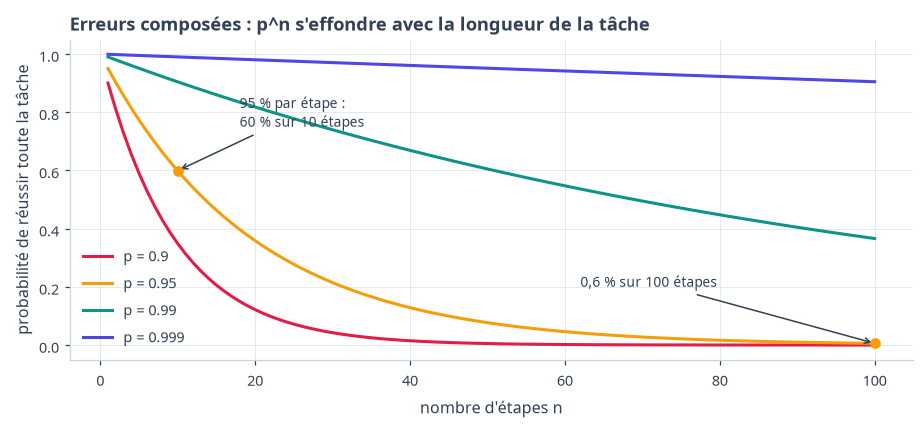

In [3]:
n = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(8.5, 4))
for p_, col in [(0.90, ROSE), (0.95, AMBER), (0.99, TEAL), (0.999, INDIGO)]:
    ax.plot(n, c6.compound_success(p_, n), color=col, label=f"p = {p_}")
ax.scatter([10, 100], c6.compound_success(0.95, [10, 100]), color=AMBER, zorder=5)
ax.annotate("95 % par étape :\n60 % sur 10 étapes", (10, 0.599), xytext=(18, 0.75), arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.annotate("0,6 % sur 100 étapes", (100, 0.006), xytext=(62, 0.2), arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.set_xlabel("nombre d'étapes n"); ax.set_ylabel("probabilité de réussir toute la tâche")
ax.set_title("Erreurs composées : p^n s'effondre avec la longueur de la tâche"); ax.legend()
plt.tight_layout(); plt.show()

Inversement, pour viser 90 % de réussite sur $n$ étapes, il faut $p \geq 0{,}9^{1/n}$ : soit
98,9 % par étape pour 10 étapes et 99,9 % pour 100. D'où l'intérêt de la **réflexion** (repérer
et corriger les erreurs en cours de route) et de tâches courtes et bien découpées.

> **À retenir.** Un agent = un environnement + des actions (outils) + un modèle qui planifie.
> La fiabilité se dégrade exponentiellement avec le nombre d'étapes ($p^n$) : chaque étape doit
> être très fiable, ou vérifiée.

## 2. Les outils (section *Tools*)

Sans outil, un LLM ne sait faire qu'une chose : produire du texte. Le livre distingue trois
catégories d'outils :

| Catégorie | Rôle | Exemples |
|---|---|---|
| Augmentation des connaissances | construire le contexte | retriever, SQL, recherche Web, API internes |
| Extension des capacités | pallier les faiblesses du modèle | calculatrice, calendrier, convertisseur, interpréteur de code |
| Actions d'écriture | agir sur l'environnement | envoyer un courriel, modifier une base, virement |

Les outils de **lecture** permettent de percevoir, ceux d'**écriture** d'agir ; les seconds
exigent une confiance et des garde-fous bien plus grands (on ne laisse pas un stagiaire effacer
la base de production). Les outils peuvent aussi rendre un modèle texte « multimodal »
(générateur d'images, transcription). Notre inventaire ne contient que des outils **sûrs**, en
lecture seule ; la calculatrice n'utilise jamais `eval` mais un évaluateur d'arbre syntaxique
qui refuse tout ce qui n'est pas de l'arithmétique.

In [4]:
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)

def recherche(q):
    return [TXT[d_] for d_, _ in c6.rrf([bm25.search(q, 10), dense.search(q, 10)])][:2]

TOOLS = c6.make_tools(recherche)
pd.DataFrame([{"outil": t.name, "description": t.description[:80], "paramètres": ", ".join(t.parameters["properties"]) or "(aucun)",
               "écriture ?": t.write} for t in TOOLS.values()])

,outil,description,paramètres,écriture ?
0,calculatrice,"Évalue une expression arithmétique (+, -, *, /, **, sqrt, round). Exemple : '3 *",expression,False
1,recherche_corpus,"Cherche dans la base documentaire interne (produits Minou Chic, thermostat Therm",requete,False
2,date_du_jour,Renvoie la date d'aujourd'hui au format AAAA-MM-JJ.,(aucun),False
3,jours_entre,Nombre de jours entre deux dates au format AAAA-MM-JJ.,"date_debut, date_fin",False


In [5]:
print(json.dumps(TOOLS["jours_entre"].schema(), ensure_ascii=False, indent=1))
for expr in ["3 * 18", "round(199999 / 292, 2)", "__import__('os').system('ls')"]:
    try:
        print(f"calculatrice({expr!r}) -> {TOOLS['calculatrice'].fn(expr)}")
    except Exception as e:
        print(f"calculatrice({expr!r}) -> refusé : {e}")

{
 "type": "function",
 "function": {
  "name": "jours_entre",
  "description": "Nombre de jours entre deux dates au format AAAA-MM-JJ.",
  "parameters": {
   "type": "object",
   "properties": {
    "date_debut": {
     "type": "string"
    },
    "date_fin": {
     "type": "string"
    }
   },
   "required": [
    "date_debut",
    "date_fin"
   ]
  }
 }
}
calculatrice('3 * 18') -> 54
calculatrice('round(199999 / 292, 2)') -> 684.93
calculatrice("__import__('os').system('ls')") -> refusé : expression non autorisée : Call(func=Attribute(value=Call(func=Name


> **À retenir.** L'inventaire d'outils définit ce que l'agent peut faire. Chaque outil est
> décrit par un nom, une description et un schéma JSON de paramètres. Les outils d'écriture
> et l'exécution de code demandent des garde-fous (bac à sable, validation humaine).

## 3. L'appel de fonctions en JSON (section *Function calling*)

Les API de modèles proposent l'**appel de fonctions** : on déclare l'inventaire, le modèle
répond soit par du texte, soit par un **appel structuré** (nom de la fonction et arguments
JSON) que **l'application** exécute avant de renvoyer le résultat au modèle. Beaucoup d'API
permettent de régler l'usage des outils : `required` (au moins un appel), `none` (aucun),
`auto` (le modèle décide). Le gabarit de conversation de Qwen2.5 injecte les signatures dans le
prompt système et attend des appels entre balises `<tool_call>` :

In [6]:
gabarit = tok.apply_chat_template([{"role": "user", "content": "Combien font 199999 divisé par 292 ?"}],
                                  tools=[TOOLS["calculatrice"].schema()], add_generation_prompt=True, tokenize=False)
print(gabarit)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "calculatrice", "description": "Évalue une expression arithmétique (+, -, *, /, **, sqrt, round). Exemple : '3 * 18'.", "parameters": {"type": "object", "properties": {"expression": {"type": "string", "description": "expression arithmétique à calculer"}}, "required": ["expression"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
Combien font 199999 divisé par 292 ?<|im_end|>
<|im_start|>assistant



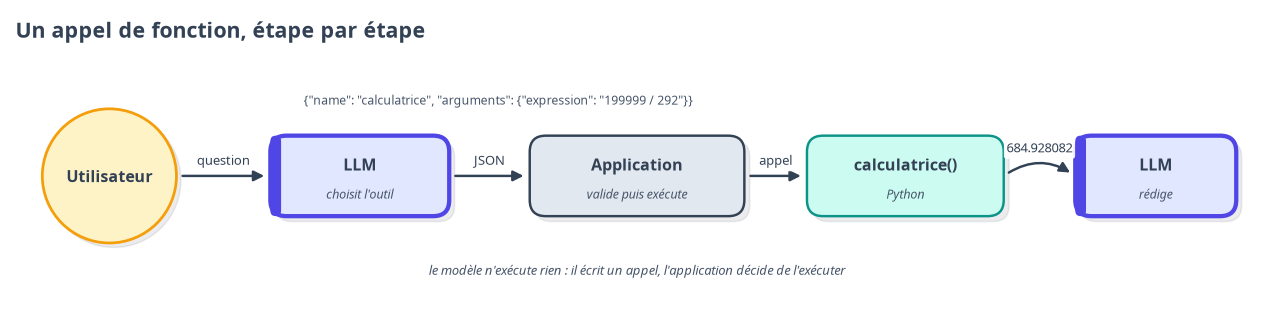

In [7]:
d = Diagram(14, 2.9, title="Un appel de fonction, étape par étape")
d.box("u", 1.1, 1.6, "Utilisateur", color=AMBER, kind="user", w=1.5)
d.box("m1", 3.9, 1.6, "LLM", sub="choisit l'outil", color=INDIGO, kind="model", w=2.0)
d.box("app", 7.0, 1.6, "Application", sub="valide puis exécute", color=SLATE, w=2.4)
d.box("f", 10.0, 1.6, "calculatrice()", sub="Python", color=TEAL, w=2.2)
d.box("m2", 12.8, 1.6, "LLM", sub="rédige", color=INDIGO, kind="model", w=1.8)
d.arrow("u", "m1", "question")
d.arrow("m1", "app", "JSON")
d.arrow("app", "f", "appel")
d.arrow("f", "m2", "684.928082", rad=-0.35)
d.note(5.45, 2.45, '{"name": "calculatrice", "arguments": {"expression": "199999 / 292"}}', fontsize=8, style="normal")
d.note(7.0, 0.55, "le modèle n'exécute rien : il écrit un appel, l'application décide de l'exécuter", fontsize=8.5)
d.show()

Donnons à Qwen les dix tâches de test du module, avec l'inventaire complet, et regardons sa
**première** décision : quel outil, avec quels arguments ? Puis le même essai en mode
« aucun outil » (`none`, simulé en ne déclarant pas d'outils).

In [8]:
schemas = [t.schema() for t in TOOLS.values()]
taches = c6.AGENT_TASKS
premiers = c6.generate_batch([[{"role": "user", "content": t["task"]}] for t in taches], max_new_tokens=80, tools=schemas)
sans_outils = c6.generate_batch([[{"role": "user", "content": t["task"]}] for t in taches], max_new_tokens=40)
lig = []
for t, out, no in zip(taches, premiers, sans_outils):
    _, calls = c6.parse_tool_calls(out)
    c = calls[0] if calls else None
    lig.append({"tâche": t["task"][:58], "outils attendus": ", ".join(t["tools"]) or "(aucun)",
                "1er appel (auto)": f"{c.get('name')}({json.dumps(c.get('arguments', {}), ensure_ascii=False)})"[:60] if c else "(texte)",
                "statut": c6.validate_call(c, TOOLS) if c else "-", "sans outils (none)": no[:50]})
pd.DataFrame(lig)

,tâche,outils attendus,1er appel (auto),statut,sans outils (none)
0,Combien coûtent 3 Fedoras Fruités chez Minou Chic ?,"recherche_corpus, calculatrice","calculatrice({""expression"": ""3 * 100""})",ok,"Je suis désolé, mais je ne peux pas fournir des in"
1,Combien font 199999 divisé par 292 ? Arrondis à deux décim,calculatrice,"calculatrice({""expression"": ""199999 / 292""})",ok,Pour calculer 199999 divisé par 292 et arrondir au
2,Quelle est la date d'aujourd'hui ?,date_du_jour,date_du_jour({}),ok,"Je suis désolé, mais je ne peux pas fournir une da"
3,Combien de jours reste-t-il entre aujourd'hui et le 31 déc,"date_du_jour, jours_entre","jours_entre({""date_debut"": ""2026-12-31"", ""date_fin"": ""2026-1",ok,Pour calculer combien de jours restent jusqu'au 31
4,Que signifie le code E-42 du thermostat Thermo-X200 ?,recherche_corpus,"recherche_corpus({""requete"": ""E-42 thermostat Thermo-X200""})",ok,"Le code ""E-42"" est un numéro unique utilisé pour i"
5,Quelle est la racine carrée de 1764 ?,calculatrice,"calculatrice({""expression"": ""sqrt(1764)""})",ok,La racine carrée de 1764 est 43.
6,Combien coûtent ensemble un Nœud Papillon Gala et un Imper,"recherche_corpus, calculatrice","calculatrice({""expression"": ""Nœud Papillon Gala + Imperméabl",ok,Pour calculer le coût total d'un Nœud Papillon Gal
7,"Combien vaut 17,5 % de 2 480 euros ?",calculatrice,"calculatrice({""expression"": ""17.5% de 2480""})",ok,"Pour calculer 17,5% de 2 480 euros, vous pouvez ut"
8,Bonjour ! Peux-tu te présenter en une phrase ?,(aucun),"calculatrice({""expression"": ""Bonjour ! Peux-tu te présenter",ok,"Bien sûr, je serai ravi de vous présenter en une p"
9,Quel temps fera-t-il demain à Lyon ?,(aucun),"recherche_corpus({""requete"": ""Lyon tomorrow weather""})",ok,"Je suis désolé, mais je ne peux pas fournir des in"


Les appels sont presque tous **syntaxiquement** valides (statut « ok » : outil existant,
paramètres attendus), et les cas simples partent vers le bon outil (racine carrée, date, code
d'erreur). Mais regardez les **valeurs** : un prix inventé (« 3 * 100 ») au lieu d'une recherche
préalable, une date de début erronée, du texte français glissé dans une expression
arithmétique, une salutation envoyée... à la calculatrice, et une question hors de portée des
outils (la météo) qui déclenche une recherche sans rapport. Le mode « auto » d'un petit modèle
sur-utilise les outils. Sans outils, le modèle répond de mémoire... et se trompe sur les calculs
et les faits fictifs. D'où le conseil du livre : **toujours inspecter les paramètres** de chaque
appel.

> **À retenir.** Dans l'appel de fonctions, le modèle **écrit** une demande structurée
> (nom + arguments JSON) et l'application l'**exécute**. Un JSON valide ne garantit pas des
> valeurs justes : il faut journaliser et vérifier chaque appel.

## 4. Planification (section *Planning*)

Une tâche est définie par un **but** et des **contraintes** ; un **plan** est la suite d'étapes
qui y mène. Planifier est un problème de **recherche** : explorer des chemins, prédire leur
résultat, revenir en arrière si besoin. Le livre recommande de **découpler** la génération du
plan de son exécution : on génère un plan, on le **valide** (heuristiques ou juge IA), et on
ne l'exécute que s'il est valide ; sinon on en génère un autre.

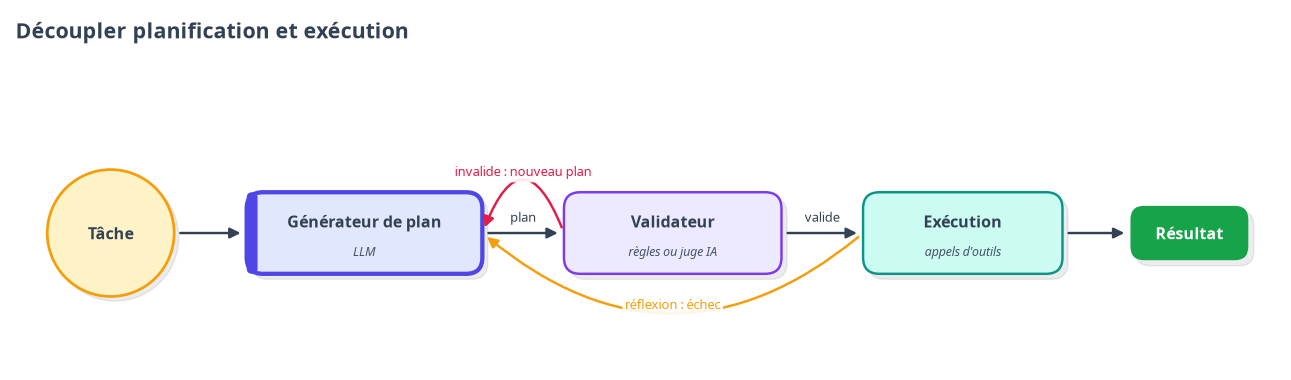

In [9]:
d = Diagram(14, 3.4, title="Découpler planification et exécution")
d.box("t", 1.1, 1.5, "Tâche", color=AMBER, kind="user", w=1.4)
d.box("gen", 3.9, 1.5, "Générateur de plan", sub="LLM", color=INDIGO, kind="model", w=2.6)
d.box("val", 7.3, 1.5, "Validateur", sub="règles ou juge IA", color=VIOLET, w=2.4)
d.box("exe", 10.5, 1.5, "Exécution", sub="appels d'outils", color=TEAL, w=2.2)
d.box("ok", 13.0, 1.5, "Résultat", color=GREEN, kind="tag", w=1.3, h=0.6)
d.arrow("t", "gen"); d.arrow("gen", "val", "plan"); d.arrow("val", "exe", "valide"); d.arrow("exe", "ok")
d.arrow("val", "gen", "invalide : nouveau plan", rad=1.3, color=ROSE, label_offset=(0, 0.1))
d.arrow("exe", "gen", "réflexion : échec", rad=-0.42, color=AMBER, label_offset=(0, 0.1))
d.show()

Reprenons l'idée du prompt de planification du livre (une liste d'actions autorisées, deux
exemples, puis la tâche), adaptée à nos outils. Pour chaque tâche, on échantillonne 5 plans à
température 0,8 (graines fixées), puis on applique deux heuristiques de validation citées par
le livre : toutes les actions existent-elles dans l'inventaire ? le plan est-il de longueur
raisonnable ? On vérifie enfin si le plan contient les outils nécessaires.

Plans valides : 40% ; plans valides et complets : 40% ; plans à générer en moyenne avant le premier valide : 1.7


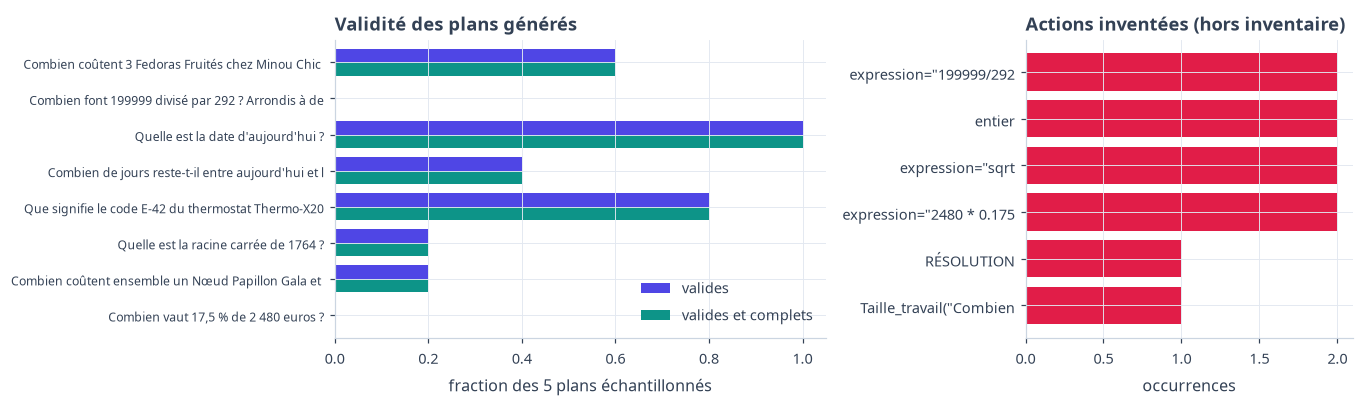

,tâche,graine,plan,raison
0,Combien coûtent 3 Fedoras Fruités chez Minou Chic,0,"[recherche_corpus, calculatrice, repondre]",ok
1,Combien coûtent 3 Fedoras Fruités chez Minou Chic,1,"[recherche_corpus, calculatrice, repondre]",ok
2,Combien coûtent 3 Fedoras Fruités chez Minou Chic,2,[RÉSOLUTION],action invalide : RÉSOLUTION
3,Combien coûtent 3 Fedoras Fruités chez Minou Chic,3,"[Taille_travail(""Combien, input_type=""amount""), recherche_corpus, calculatrice, repondre]","action invalide : Taille_travail(""Combien"
4,Combien coûtent 3 Fedoras Fruités chez Minou Chic,4,"[recherche_corpus, calculatrice, repondre]",ok
5,Combien font 199999 divisé par 292 ? Arrondis à de,0,"[calculatrice, expression=""199999/292, output=round]","action invalide : expression=""199999/292"
6,Combien font 199999 divisé par 292 ? Arrondis à de,1,"[calculatrice, entier]",action invalide : entier
7,Combien font 199999 divisé par 292 ? Arrondis à de,2,"[calculatrice, expression=""199999/292, resultat=""78.34]","action invalide : expression=""199999/292"
8,Combien font 199999 divisé par 292 ? Arrondis à de,3,"[calculatrice, expression=""fractions.divide(199999, output_format=""two_decimal_places]","action invalide : expression=""fractions.divide(199999"
9,Combien font 199999 divisé par 292 ? Arrondis à de,4,"[calculatrice, expression, repondre]",action invalide : expression


In [10]:
PLAN_SYS = ("Propose un plan pour résoudre la tâche. Actions disponibles :\n"
            "date_du_jour()\njours_entre(date_debut, date_fin)\nrecherche_corpus(requete)\ncalculatrice(expression)\n"
            "repondre(texte)\n\nLe plan doit être une liste d'actions valides entre crochets.\n\nExemples\n"
            "Tâche : « Quel est le prix du Pull Torsadé ? »\nPlan : [recherche_corpus, repondre]\n"
            "Tâche : « Combien de jours depuis le 1er mars ? »\nPlan : [date_du_jour, jours_entre, repondre]")
ACTIONS = set(TOOLS) | {"repondre"}
plan_rows = []
for t in taches[:8]:
    for seed in range(5):
        out = llm.chat(f"Tâche : « {t['task']} »\nPlan :", system=PLAN_SYS, max_new_tokens=40, temperature=0.8, seed=seed)
        plan = c6.parse_plan(out)
        valide, raison = c6.validate_plan(plan, ACTIONS, max_steps=6)
        plan_rows.append({"tâche": t["task"][:50], "graine": seed, "plan": plan, "valide": valide, "raison": raison,
                          "complet": valide and set(t["tools"]) <= set(plan)})
plans = pd.DataFrame(plan_rows)
par_tache = plans.groupby("tâche", sort=False).agg(valides=("valide", "mean"), complets=("complet", "mean"))
essais = plans.groupby("tâche", sort=False)["valide"].apply(lambda v: (list(v).index(True) + 1) if any(v) else np.nan)
print(f"Plans valides : {plans.valide.mean():.0%} ; plans valides et complets : {plans.complet.mean():.0%} ; "
      f"plans à générer en moyenne avant le premier valide : {essais.mean():.1f}")
inval = pd.Series([r.split(": ", 1)[1] for r in plans.raison if r.startswith("action invalide")]).value_counts().head(6)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
par_tache.plot.barh(ax=axes[0], color=[INDIGO, TEAL], width=0.75)
axes[0].invert_yaxis(); axes[0].set_xlim(0, 1.05); axes[0].set_xlabel("fraction des 5 plans échantillonnés")
axes[0].set_title("Validité des plans générés"); axes[0].legend(["valides", "valides et complets"], loc="lower right")
axes[0].tick_params(axis="y", labelsize=8); axes[0].set_ylabel("")
if len(inval):
    axes[1].barh(inval.index[::-1], inval.values[::-1], color=ROSE)
axes[1].set_title("Actions inventées (hors inventaire)"); axes[1].set_xlabel("occurrences")
finish(fig); plt.show()
plans[["tâche", "graine", "plan", "raison"]].head(10)

Le validateur est indispensable : une partie des plans contient des actions **inventées**
(des noms plausibles qui n'existent pas dans l'inventaire) ou oublie un outil nécessaire, et
le valider ne coûte presque rien comparé à exécuter un mauvais plan. Le livre liste les leviers
pour améliorer la planification : meilleur prompt système avec plus d'exemples, meilleures
descriptions des outils, outils plus simples, modèle plus fort, affinage.

**Granularité et flux de contrôle.** Un plan peut être formulé avec les noms exacts des
fonctions (facile à exécuter, mais fragile si l'inventaire change) ou en langage naturel (plus
robuste, mais il faut un « traducteur » vers des commandes exécutables). Il peut aussi être
hiérarchique (plan général puis sous-plans). Et il n'est pas forcément séquentiel :

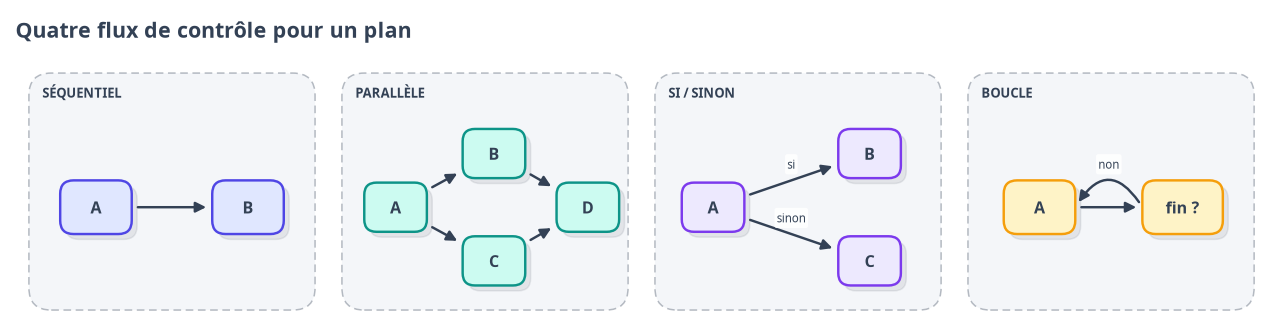

In [11]:
d = Diagram(14, 2.9, title="Quatre flux de contrôle pour un plan")
specs = [("séquentiel", 0.2), ("parallèle", 3.7), ("si / sinon", 7.2), ("boucle", 10.7)]
for titre_, x0 in specs:
    d.group(x0, 0.1, x0 + 3.2, 2.75, titre_, color=SLATE)
d.box("sa", 0.95, 1.25, "A", color=INDIGO, w=0.8, h=0.6); d.box("sb", 2.65, 1.25, "B", color=INDIGO, w=0.8, h=0.6); d.arrow("sa", "sb")
d.box("pa", 4.3, 1.25, "A", color=TEAL, w=0.7, h=0.55); d.box("pb", 5.4, 1.85, "B", color=TEAL, w=0.7, h=0.55)
d.box("pc", 5.4, 0.65, "C", color=TEAL, w=0.7, h=0.55); d.box("pd", 6.45, 1.25, "D", color=TEAL, w=0.7, h=0.55)
d.arrow("pa", "pb"); d.arrow("pa", "pc"); d.arrow("pb", "pd"); d.arrow("pc", "pd")
d.box("ia", 7.85, 1.25, "A", color=VIOLET, w=0.7, h=0.55); d.box("ib", 9.6, 1.85, "B", color=VIOLET, w=0.7, h=0.55)
d.box("ic", 9.6, 0.65, "C", color=VIOLET, w=0.7, h=0.55); d.arrow("ia", "ib", "si", fontsize=7.5); d.arrow("ia", "ic", "sinon", fontsize=7.5)
d.box("la", 11.5, 1.25, "A", color=AMBER, w=0.8, h=0.6); d.box("lb", 13.1, 1.25, "fin ?", color=AMBER, w=0.9, h=0.6)
d.arrow("la", "lb"); d.arrow("lb", "la", "non", rad=0.8, fontsize=7.5)
d.show()

Le parallélisme réduit la latence perçue (consulter dix sites à la fois) ; les conditions et
les boucles sont plus difficiles à générer et à traduire en commandes. Avec un agent, c'est le
modèle qui décide du flux, là où un programme classique a des conditions exactes.

> **À retenir.** Générer un plan, le **valider** à peu de frais (actions existantes, longueur,
> outils nécessaires), puis l'exécuter. Les plans générés par un LLM contiennent des actions
> inventées et des paramètres hallucinés : on ne les exécute jamais sans contrôle.

## 5. La boucle ReAct (section *Reflection and error correction*)

ReAct (Yao et al., 2022) **entrelace raisonnement et action** : à chaque étape, l'agent
explique sa réflexion, agit (appel d'outil), lit l'**observation**, et recommence jusqu'à
juger la tâche terminée. Le « raisonnement » englobe planification et réflexion. Notre
fonction `c6.run_agent` implémente cette boucle autour de l'appel de fonctions natif de Qwen :
chaque résultat d'outil, ou chaque **erreur**, est réinjecté dans la conversation comme
observation ; un budget d'étapes évite les boucles infinies.

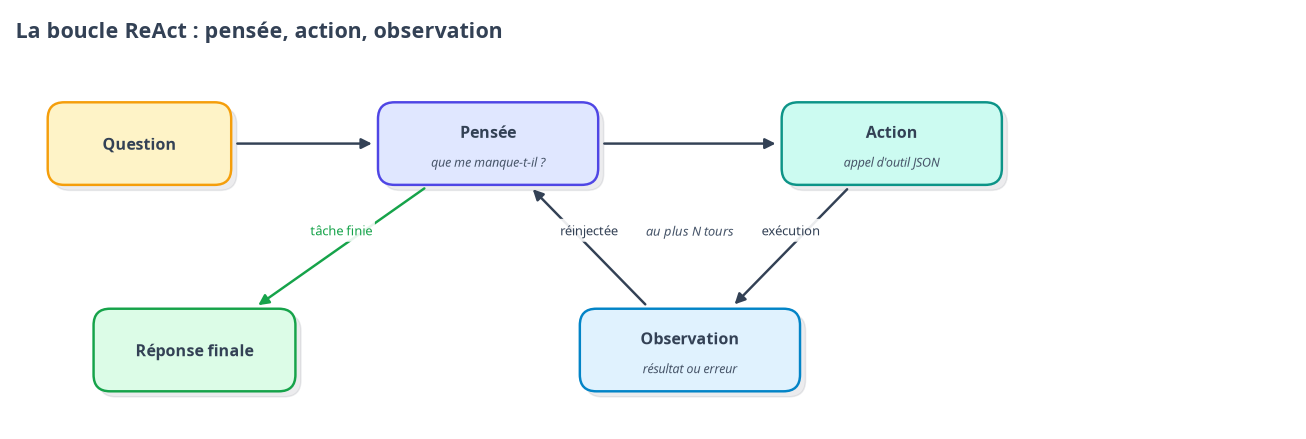

In [12]:
d = Diagram(14, 4.0, title="La boucle ReAct : pensée, action, observation")
d.box("q", 1.4, 3.1, "Question", color=AMBER, w=2.0)
d.box("th", 5.2, 3.1, "Pensée", sub="que me manque-t-il ?", color=INDIGO, w=2.4)
d.box("ac", 9.6, 3.1, "Action", sub="appel d'outil JSON", color=TEAL, w=2.4)
d.box("ob", 7.4, 0.85, "Observation", sub="résultat ou erreur", color=SKY, w=2.4)
d.box("fin", 2.0, 0.85, "Réponse finale", color=GREEN, w=2.2)
d.arrow("q", "th"); d.arrow("th", "ac"); d.arrow("ac", "ob", "exécution"); d.arrow("ob", "th", "réinjectée")
d.arrow("th", "fin", "tâche finie", rad=0.0, color=GREEN)
d.note(7.4, 2.15, "au plus N tours", fontsize=8.5)
d.show()

In [13]:
SYS_SIMPLE = "Tu es un assistant qui peut utiliser des outils. Réponds en une phrase en français."
SYS_REGLES = ("Tu es un assistant qui utilise des outils. Règles : (1) pour toute information sur des produits, des "
              "entreprises ou des documents internes, appelle d'abord recherche_corpus, n'invente jamais un prix ou un fait ; "
              "(2) pour tout calcul, appelle calculatrice avec une expression Python (17,5 % de X s'écrit 0.175 * X) ; "
              "(3) pour les dates, appelle date_du_jour puis jours_entre ; (4) si aucun outil ne permet de répondre, dis-le ; "
              "(5) quand tu as la réponse, réponds en une phrase.")

def evaluer(nom, step, system, tools=TOOLS, critic=None):
    lignes, resultats = [], []
    for t in taches:
        t0 = time.perf_counter()
        r = c6.run_agent(t["task"], tools, step, max_steps=5, system=system, critic=critic)
        resultats.append(r)
        lignes.append({"config": nom, "tâche": t["task"][:45], "issue": c6.classify_run(t, r), "étapes": len(r.steps),
                       "appels": r.n_tool_calls, "latence (s)": time.perf_counter() - t0, "outils": r.tools_used})
    return pd.DataFrame(lignes), resultats

step_05 = c6.make_qwen_step(llm.SMALL)
df_a, res_a = evaluer("0,5B consigne simple", step_05, SYS_SIMPLE)
for i in [0, 3, 4]:
    print(res_a[i].trace(100), end="\n\n")
df_a[["tâche", "issue", "étapes", "appels", "outils"]]

Question : Combien coûtent 3 Fedoras Fruités chez Minou Chic ?
  Action 1      : {"name": "calculatrice", "arguments": {"expression": "3 * 35.99"}}  [ok]
  Observation 1 : 107.97
  Pensée 2      : Le coût pour 3 Fedoras Fruités chez Minou Chic est environ 107.97€.
  Réponse finale : Le coût pour 3 Fedoras Fruités chez Minou Chic est environ 107.97€.

Question : Combien de jours reste-t-il entre aujourd'hui et le 31 décembre 2026 ?
  Action 1      : {"name": "jours_entre", "arguments": {"date_debut": "2026-12-31", "date_fin": "2026-12-31"}}  [ok]
  Observation 1 : 0
  Pensée 2      : Il reste 0 jours entre aujourd'hui et le 31 décembre 2026.
  Réponse finale : Il reste 0 jours entre aujourd'hui et le 31 décembre 2026.

Question : Que signifie le code E-42 du thermostat Thermo-X200 ?
  Pensée 1      : Le code E-42 est un numéro unique pour le modèle Thermo-X200 de l'entreprise Thermomix. Il s'agit d'
  Réponse finale : Le code E-42 est un numéro unique pour le modèle Thermo-X200 de l'ent

,tâche,issue,étapes,appels,outils
0,Combien coûtent 3 Fedoras Fruités chez Minou,outil nécessaire non utilisé,2,1,[calculatrice]
1,Combien font 199999 divisé par 292 ? Arrondis,valeurs ou réponse incorrectes,2,1,[calculatrice]
2,Quelle est la date d'aujourd'hui ?,succès,2,1,[date_du_jour]
3,Combien de jours reste-t-il entre aujourd'hui,outil nécessaire non utilisé,2,1,[jours_entre]
4,Que signifie le code E-42 du thermostat Therm,outil nécessaire non utilisé,1,0,[]
5,Quelle est la racine carrée de 1764 ?,succès,2,1,[calculatrice]
6,Combien coûtent ensemble un Nœud Papillon Gal,outil nécessaire non utilisé,1,0,[]
7,"Combien vaut 17,5 % de 2 480 euros ?",erreur d'exécution,2,1,[calculatrice]
8,Bonjour ! Peux-tu te présenter en une phrase,succès,1,0,[]
9,Quel temps fera-t-il demain à Lyon ?,hallucination (outil manquant),2,1,[recherche_corpus]


Lisez les traces : la boucle fonctionne (appel, observation, réponse), mais le modèle de 0,5 B
commet des erreurs typiques que la section suivante catégorise : sauter la recherche et
**inventer** un prix, appeler le bon outil avec de **mauvaises valeurs** (une date de début
erronée), répondre à une question hors de portée sans le dire.

> **À retenir.** ReAct = boucle « pensée -> action -> observation » jusqu'à la réponse finale.
> Réinjecter les observations, y compris les **erreurs**, permet au modèle de se corriger ; un
> budget d'étapes borne le coût.

## 6. Réflexion et correction d'erreurs (section *Reflection and error correction*)

La réflexion peut intervenir à plusieurs moments : avant d'agir (la requête est-elle
faisable ?), après le plan, après chaque étape, et à la fin (la tâche est-elle accomplie ?).
Elle peut être faite par le même modèle (auto-critique) ou par un **composant spécialisé** qui
note le résultat. Reflexion (Shinn et al., 2023) sépare un **évaluateur** et un module
d'**auto-réflexion** qui explique l'échec, puis l'agent repart avec ce retour.

Implémentons un évaluateur spécialisé, sans LLM : un **vérificateur d'ancrage** qui exige que
chaque nombre de la réponse finale provienne de la question ou d'une observation d'outil, et
qui repère les annonces sans action (« je vais chercher... »). S'il échoue, son retour est
ajouté à la conversation et l'agent reprend (une fois au plus). Comparons, à consigne détaillée
égale, l'agent sans et avec ce vérificateur.

In [14]:
df_b, res_b = evaluer("0,5B consigne détaillée", step_05, SYS_REGLES)
df_c, res_c = evaluer("0,5B détaillée + vérificateur", step_05, SYS_REGLES, critic=c6.grounding_critic)
reflechis = [r for r in res_c if any(s.status == "réflexion" for s in r.steps)]
print(f"Le vérificateur est intervenu sur {len(reflechis)} tâches sur {len(taches)}.\n")
if reflechis:
    r = reflechis[0]
    print(r.question)
    for s in r.steps:
        if s.status == "réflexion":
            print(f"  [vérificateur] {s.observation[:110]}")
        elif s.call is not None:
            print(f"  Action : {json.dumps(s.call, ensure_ascii=False)[:90]}  ->  {s.observation.replace(chr(10), ' ')[:60]}")
        else:
            print(f"  Réponse : {s.thought[:100]}")

Le vérificateur est intervenu sur 1 tâches sur 10.

Quel temps fera-t-il demain à Lyon ?
  Action : {"name": "date_du_jour", "arguments": {}}  ->  2026-11-25
  Réponse : Le temps prévu pour demain à Lyon est de 20h30.
  [vérificateur] Vérification : le nombre 20 de ta réponse ne provient d'aucun résultat d'outil. Utilise les outils (recherche_
  Réponse : La réponse contient probablement un outil spécifique. Pourriez-vous fournir plus de détails sur ce q


Le vérificateur ne peut pas rendre le modèle plus intelligent, mais il **détecte** une classe
d'erreurs (chiffre non justifié, action annoncée mais non faite) et donne au modèle une seconde
chance avec une consigne précise. Il a ses propres modes d'échec : une première version de ce
vérificateur rejetait « 684,93 » parce que l'outil avait renvoyé « 684.928082 » ; il accepte
désormais les arrondis. Un évaluateur se teste comme n'importe quel composant (voir les tests du
module), et la reprise qu'il déclenche n'est pas garantie de mieux faire. C'est l'esprit de Reflexion : l'évaluation est souvent plus
facile que la génération. Son coût : des tokens et de la latence en plus à chaque reprise.

> **À retenir.** Réflexion = **évaluer** (règles, score spécialisé ou auto-critique) puis
> **corriger** avec un retour explicite. Facile à ajouter, souvent rentable, mais elle coûte
> des tokens et de la latence.

## 7. Modes d'échec et évaluation (section *Agent Failure Modes and Evaluation*)

Évaluer un agent, c'est identifier ses **modes d'échec** et mesurer leur fréquence. Le livre
distingue :

- **échecs de planification** : outil invalide (inventé), outil valide avec paramètres
  invalides, outil valide avec **valeurs** incorrectes ; échec du **but** (tâche non résolue ou
  contraintes non respectées) ; erreur de réflexion (l'agent croit avoir fini) ;
- **échecs d'outil** : l'outil renvoie un résultat faux, ou l'outil nécessaire **manque** ;
- **efficacité** : nombre d'étapes, coût, latence.

Notre fonction `c6.classify_run` attribue une catégorie à chaque exécution. Ajoutons une
quatrième configuration : Qwen2.5-**1,5B** (sur CPU) avec la consigne détaillée, pour tester
l'affirmation du livre selon laquelle les agents demandent des modèles plus forts.

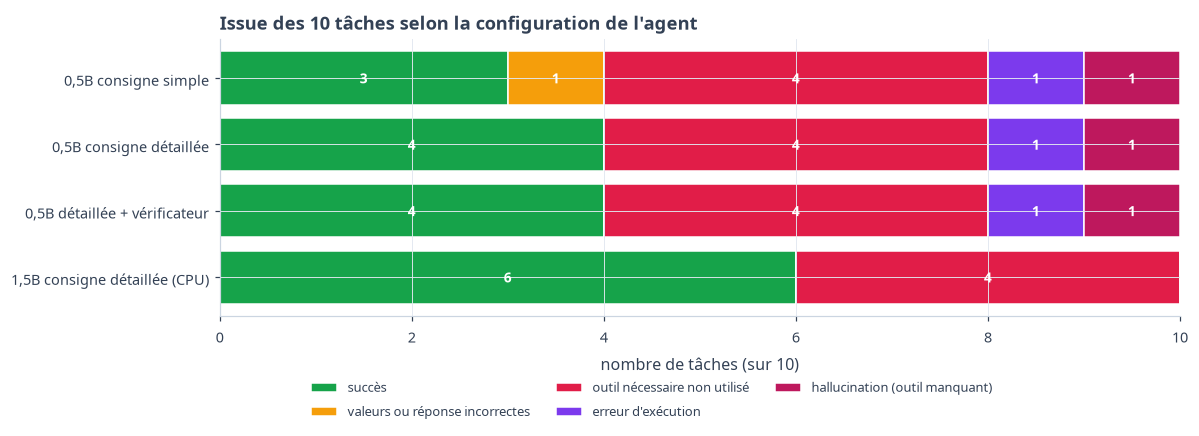

In [15]:
step_15 = c6.make_qwen_step(llm.MEDIUM, device="cpu")
df_d, res_d = evaluer("1,5B consigne détaillée (CPU)", step_15, SYS_REGLES)
toutes = pd.concat([df_a, df_b, df_c, df_d])
ordre = ["succès", "valeurs ou réponse incorrectes", "outil nécessaire non utilisé", "erreur d'exécution",
         "paramètres invalides", "outil inventé", "JSON invalide", "appel inutile", "hallucination (outil manquant)",
         "budget d'étapes épuisé"]
couleurs = [GREEN, AMBER, ROSE, VIOLET, SKY, INDIGO, SLATE, GRAY, "#BE185D", "#78350F"]
tab = pd.crosstab(toutes["config"], toutes["issue"]).reindex(columns=[o for o in ordre if o in set(toutes["issue"])], fill_value=0)
tab = tab.reindex(df_a.config[:1].tolist() + df_b.config[:1].tolist() + df_c.config[:1].tolist() + df_d.config[:1].tolist())
fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(tab))
for col_name in tab.columns:
    v = tab[col_name].values
    ax.barh(tab.index, v, left=left, color=couleurs[ordre.index(col_name)], label=col_name, edgecolor="white")
    for i, (l_, w_) in enumerate(zip(left, v)):
        if w_:
            ax.text(l_ + w_ / 2, i, str(w_), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += v
ax.invert_yaxis(); ax.set_xlabel("nombre de tâches (sur 10)"); ax.set_xlim(0, 10)
ax.set_title("Issue des 10 tâches selon la configuration de l'agent")
ax.legend(ncol=3, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.45, -0.18))
plt.tight_layout(); plt.show()

In [16]:
effic = toutes.groupby("config", sort=False).agg(succès=("issue", lambda s: (s == "succès").mean()),
                                                 étapes=("étapes", "mean"), appels=("appels", "mean"),
                                                 latence_s=("latence (s)", "mean"))
effic["tokens lus (total)"] = [step_05.tokens_in if "0,5B" in c else step_15.tokens_in for c in effic.index]
effic.loc[effic.index.str.contains("0,5B"), "tokens lus (total)"] = np.nan  # compteur partagé par les 3 configs 0,5B
effic.round(2)

,succès,étapes,appels,latence_s,tokens lus (total)
config,,,,,
"0,5B consigne simple",0.3,1.7,0.7,0.71,NaN
"0,5B consigne détaillée",0.4,1.9,0.9,0.79,NaN
"0,5B détaillée + vérificateur",0.4,2.1,0.9,0.51,NaN
"1,5B consigne détaillée (CPU)",0.6,1.5,0.5,4.49,9311.0


Ce tableau de bord est **l'évaluation de l'agent** : taux de succès, répartition des échecs,
nombre moyen d'étapes et latence (le compteur de tokens de l'étape 0,5B est partagé par les trois
configurations, d'où son absence). Avec dix tâches, chaque tâche vaut 10 points : on lit des
tendances, pas des décimales, et un écart d'une tâche n'est pas significatif. Le modèle de
1,5 B est le plus fiable des quatre (moins d'appels inutiles et d'erreurs de valeurs), au prix
d'une latence bien plus élevée (ici sur CPU) : c'est l'affirmation du livre, « les agents
demandent des modèles plus forts ». Pour le 0,5 B, consigne détaillée et vérificateur ne
changent le résultat qu'à la marge : ils corrigent une erreur ici, en provoquent une autre là
(une seconde tentative peut aussi dégrader une réponse). Aucune configuration n'est fiable :
à cette taille, l'agent reste un prototype, et seule une évaluation par catégories d'échec
permet de savoir quoi corriger.

**Choix des outils.** Le livre conseille de comparer des inventaires, de faire des **ablations**
(retirer un outil et mesurer la baisse) et de tracer la **distribution des appels**. Retirons
la calculatrice à la configuration « consigne détaillée » :

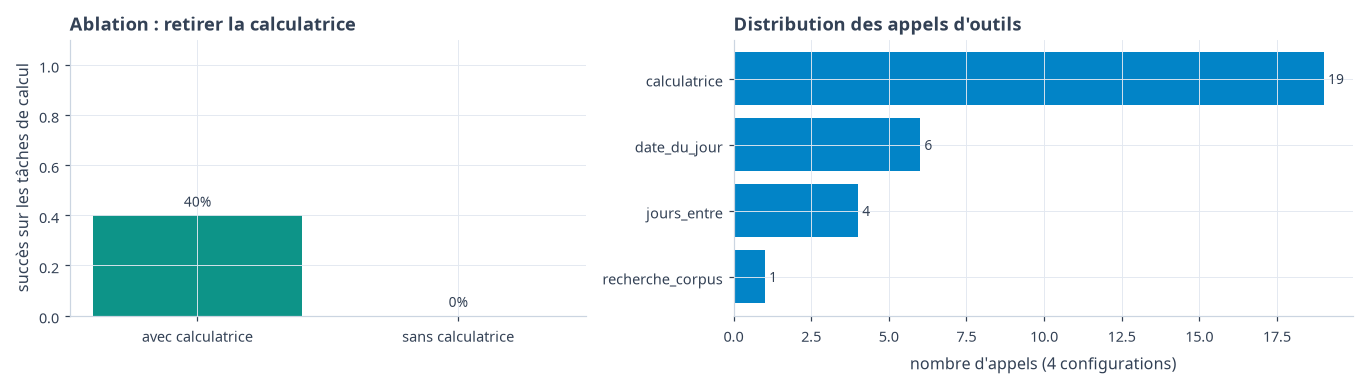

,avec calculatrice,sans calculatrice
Combien coûtent 3 Fedoras Fruités chez Minou Chic ?,False,False
Combien font 199999 divisé par 292 ? Arrondis à deux dé,True,False
Quelle est la racine carrée de 1764 ?,True,False
Combien coûtent ensemble un Nœud Papillon Gala et un Im,False,False
"Combien vaut 17,5 % de 2 480 euros ?",False,False


In [17]:
sans_calc = {k_: v for k_, v in TOOLS.items() if k_ != "calculatrice"}
df_e, _ = evaluer("0,5B détaillée, sans calculatrice", step_05, SYS_REGLES.replace("appelle calculatrice avec une expression Python (17,5 % de X s'écrit 0.175 * X)", "calcule toi-même"), tools=sans_calc)
calc_tasks = [i for i, t in enumerate(taches) if "calculatrice" in t["tools"]]
abl = pd.DataFrame({"avec calculatrice": [(df_b.issue.iloc[i] == "succès") for i in calc_tasks],
                    "sans calculatrice": [(df_e.issue.iloc[i] == "succès") for i in calc_tasks]},
                   index=[taches[i]["task"][:55] for i in calc_tasks])
usage = pd.Series([o for lst in toutes["outils"] for o in lst]).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].bar(abl.columns, abl.mean().values, color=[TEAL, ROSE]); annotate_bars(axes[0], "{:.0%}")
axes[0].set_ylim(0, 1.1); axes[0].set_ylabel("succès sur les tâches de calcul"); axes[0].set_title("Ablation : retirer la calculatrice")
axes[1].barh(usage.index[::-1], usage.values[::-1], color=SKY); annotate_bars(axes[1], "{:.0f}")
axes[1].set_xlabel("nombre d'appels (4 configurations)"); axes[1].set_title("Distribution des appels d'outils")
finish(fig); plt.show()
abl

Sans calculatrice, le petit modèle doit calculer « de tête », ce qu'il fait mal (le livre cite
199 999 / 292 comme exemple typique) : l'ablation mesure la valeur d'un outil. La distribution
des appels montre quels outils sont réellement utilisés ; un outil jamais appelé est un candidat
au retrait (il coûte des tokens de description à chaque requête), un outil souvent mal appelé
doit être simplifié ou mieux documenté. Le livre évoque aussi la **transition** entre outils
(après X, quelle probabilité d'appeler Y ?) pour composer des outils plus gros, et les
bibliothèques de compétences (Voyager) où l'agent conserve les programmes qui ont réussi.

> **À retenir.** Évaluer un agent : définir des tâches avec résultat attendu, **classer**
> chaque exécution selon les modes d'échec (planification, outil, efficacité), suivre succès,
> étapes, coût et latence, et faire des **ablations** d'outils.

## 8. La mémoire (section *Memory*)

Un modèle dispose de trois mécanismes de mémoire :

- la **connaissance interne** (ses poids) : disponible pour toute requête, ne change qu'en
  réentraînant ;
- la **mémoire à court terme** (son contexte) : rapide mais limitée, perdue entre les tâches ;
- la **mémoire à long terme** (sources externes accessibles par recherche, comme un RAG) :
  persistante, extensible, effaçable sans toucher au modèle.

Règle du livre : une information utile à toutes les tâches va dans les poids (entraînement,
affinage), une information rare dans la mémoire longue, et le contexte reste réservé à
l'immédiat.

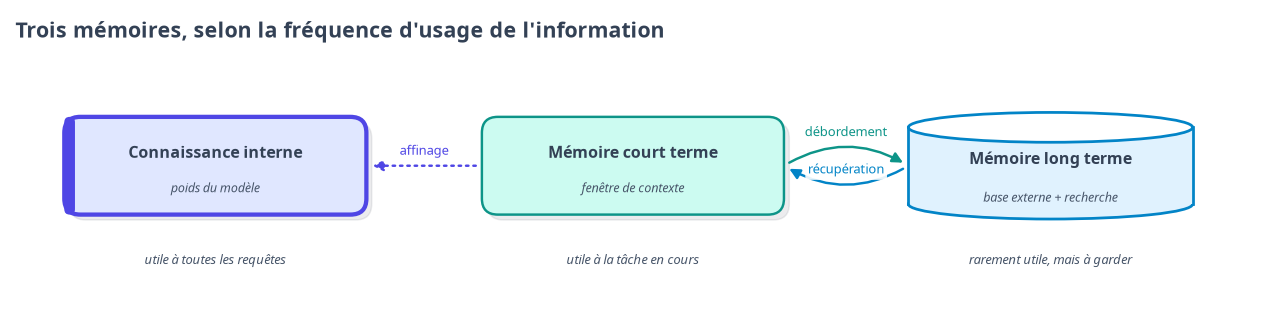

In [18]:
d = Diagram(14, 2.7, title="Trois mémoires, selon la fréquence d'usage de l'information")
d.box("int", 2.3, 1.5, "Connaissance interne", sub="poids du modèle", color=INDIGO, kind="model", w=3.4, h=1.1)
d.box("ctx", 7.0, 1.5, "Mémoire court terme", sub="fenêtre de contexte", color=TEAL, w=3.4, h=1.1)
d.box("ext", 11.7, 1.5, "Mémoire long terme", sub="base externe + recherche", color=SKY, kind="db", w=3.2, h=1.2)
d.note(2.3, 0.45, "utile à toutes les requêtes", fontsize=8.5)
d.note(7.0, 0.45, "utile à la tâche en cours", fontsize=8.5)
d.note(11.7, 0.45, "rarement utile, mais à garder", fontsize=8.5)
d.arrow("ext", "ctx", "récupération", rad=-0.3, color=SKY)
d.arrow("ctx", "ext", "débordement", rad=-0.3, color=TEAL)
d.arrow("ctx", "int", "affinage", style="dotted", color=INDIGO)
d.show()

Une mémoire apporte : la gestion du **débordement** d'information pendant une tâche, la
**persistance** entre sessions (un coach qui se souvient de vous), la **cohérence** des réponses
et le stockage de **données structurées** (tables, files d'actions). Elle repose sur deux
fonctions : la **gestion** (que garder en court terme, que déplacer ou supprimer) et la
**récupération**. Si l'on réserve une part $\rho$ du contexte $C$ à la mémoire longue (par
exemple 30 %), la mémoire courte dispose de $(1-\rho)\,C$ tokens ; au-delà, il faut évincer.

**Expérience.** Une conversation synthétique de 40 échanges sur la préparation d'un voyage
contient 8 faits personnels (nom, allergie, budget, ville de départ, chien, préférence, sœur,
date de retour), énoncés à intervalles réguliers, le premier dès le tour 0 ; le reste est du
bavardage touristique. Sous un budget de $B$ tokens, quatre stratégies d'éviction :

- **FIFO** : garder les messages les plus récents (ce que font de nombreuses API et cadriciels) ;
- **début + fin** : épingler les 2 premiers messages (souvent l'objectif), puis les plus récents ;
- **résumé** : remplacer les anciens messages par un résumé rédigé par Qwen (40 % du budget) ;
- **récupération** : moitié du budget pour les messages récents, l'autre pour les anciens
  messages les plus proches de la question posée (mémoire longue interrogée par embeddings).

On mesure la **rétention** : la part des 8 faits encore présents dans le contexte construit.

Conversation : 80 messages, 1451 tokens Qwen
Exemples : ["Je m'appelle Léa et je prépare un voyage en Italie cet été.", "C'est noté, j'en tiendrai compte pour la suite.", 'Y a-t-il un marché intéressant à Vérone ?', 'Le marché couvert de Vérone est très animé le samedi matin ; on y trouve fromages, fruits et spécialités locales.']


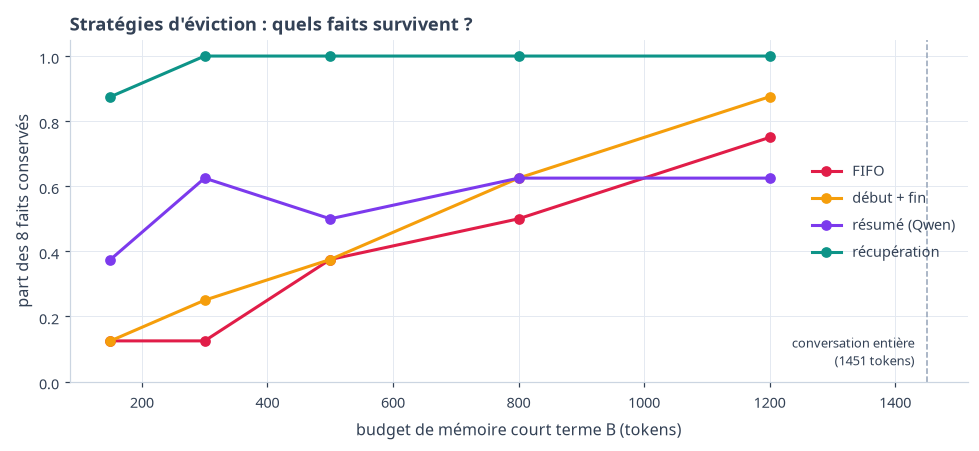

,150,300,500,800,1200
FIFO,0.12,0.12,0.38,0.50,0.75
début + fin,0.12,0.25,0.38,0.62,0.88
résumé (Qwen),0.38,0.62,0.50,0.62,0.62
récupération,0.88,1.00,1.00,1.00,1.00


In [19]:
conv = c6.make_conversation(40, seed=0)
tot = sum(ntok(m["content"]) for m in conv)
print(f"Conversation : {len(conv)} messages, {tot} tokens Qwen")
print("Exemples :", [m["content"] for m in conv[:4]])
emb = lambda xs: llm.embed(xs, llm.EMBED_MULTI)  # noqa: E731
SUM_PROMPT = ("Voici le début d'une conversation entre une utilisatrice et un assistant de voyage :\n{c}\n\n"
              "Résume en quelques phrases courtes les informations personnelles importantes données par "
              "l'utilisatrice (nom, contraintes, budget, préférences, dates, personnes). Ne mentionne pas les conseils touristiques.")
cache_resumes = {}

def resumer(old):
    if len(old) not in cache_resumes:
        txt = "\n".join(("Utilisatrice : " if m["role"] == "user" else "Assistant : ") + m["content"] for m in old)
        cache_resumes[len(old)] = c6.generate_batch([SUM_PROMPT.format(c=txt)], max_new_tokens=120)[0]
    return cache_resumes[len(old)]

budgets = [150, 300, 500, 800, 1200]
strat = {
    "FIFO": lambda B, q: c6.memory_fifo(conv, B, ntok),
    "début + fin": lambda B, q: c6.memory_head_tail(conv, B, 2, ntok),
    "résumé (Qwen)": lambda B, q: c6.memory_summary(conv, B, resumer, 0.4, ntok),
    "récupération": lambda B, q: c6.memory_retrieval(conv, B, q, emb, 0.5, ntok),
}
ret = {}
for nom, f in strat.items():
    ret[nom] = [np.mean([c6.fact_retention(f(B, fact[1]))[i] for i, fact in enumerate(c6.MEMORY_FACTS)]) for B in budgets]
fig, ax = plt.subplots(figsize=(9, 4.2))
for (nom, v), col in zip(ret.items(), [ROSE, AMBER, VIOLET, TEAL]):
    ax.plot(budgets, v, marker="o", color=col, label=nom)
ax.axvline(tot, color=GRAY, ls="--", lw=1)
ax.text(tot - 20, 0.05, f"conversation entière\n({tot} tokens)", ha="right", fontsize=8.5, color=SLATE)
ax.set_xlabel("budget de mémoire court terme B (tokens)"); ax.set_ylabel("part des 8 faits conservés")
ax.set_ylim(0, 1.05); ax.set_title("Stratégies d'éviction : quels faits survivent ?"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()
pd.DataFrame(ret, index=budgets).T.round(2)

**FIFO** oublie d'abord... le début, c'est-à-dire le nom et le but du voyage : l'hypothèse « les
vieux messages sont les moins utiles » est ici fausse, exactement comme le prévient le livre.
Épingler le début corrige ce cas précis. Le **résumé** compresse beaucoup de messages en peu de
tokens, mais celui de Qwen2.5-0.5B est bavard et oublie ou déforme des faits : sa qualité borne
la stratégie. La **récupération**, interrogée avec la question, retrouve presque toujours le
bon fait même avec un petit budget : c'est la mémoire longue à l'œuvre (au prix d'un
embedding par message et d'une recherche par tour). Vérifions avec le modèle : à budget de 300
tokens, Qwen répond-il aux 8 questions ?

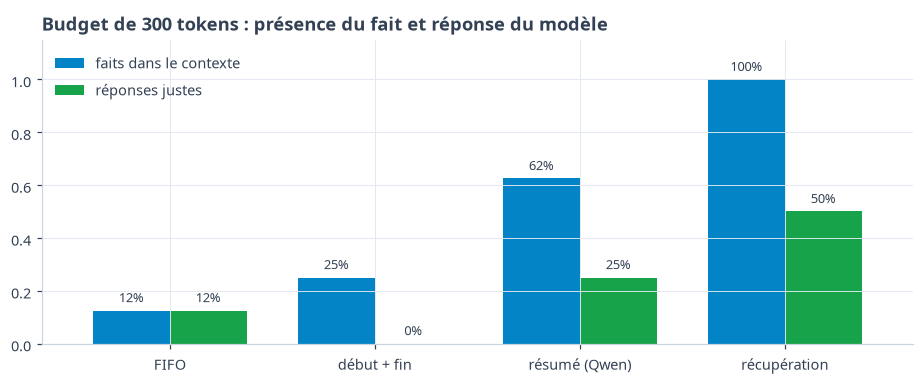

,faits dans le contexte,réponses justes
FIFO,0.12,0.12
début + fin,0.25,0.00
résumé (Qwen),0.62,0.25
récupération,1.00,0.50


In [20]:
B = 300
qa = {}
for nom, f in strat.items():
    msgs_qa = []
    for fact in c6.MEMORY_FACTS:
        ctx_ = f(B, fact[1])
        histo = [{"role": m["role"], "content": m["content"]} for m in ctx_]
        msgs_qa.append([{"role": "system", "content": "Tu es un assistant de voyage. Réponds en une phrase courte."}] + histo
                       + [{"role": "user", "content": fact[1]}])
    rep = c6.generate_batch(msgs_qa, max_new_tokens=30)
    qa[nom] = {"faits dans le contexte": np.mean([c6.fact_retention(f(B, fact[1]))[i] for i, fact in enumerate(c6.MEMORY_FACTS)]),
               "réponses justes": np.mean([c6.answer_ok(r_, fact[2]) for r_, fact in zip(rep, c6.MEMORY_FACTS)])}
qa = pd.DataFrame(qa).T
ax = qa.plot.bar(figsize=(8.5, 3.6), color=[SKY, GREEN], rot=0, width=0.75)
annotate_bars(ax, "{:.0%}", fontsize=8.5); ax.set_ylim(0, 1.15); ax.set_xlabel("")
ax.set_title(f"Budget de {B} tokens : présence du fait et réponse du modèle"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
qa.round(2)

Avoir le fait dans le contexte est nécessaire mais pas suffisant : le modèle doit encore le
lire et l'utiliser (l'écart entre les deux barres est la part du générateur, comme au cours 3).
Le livre mentionne des stratégies plus fines : éliminer la **redondance** (le langage est
redondant), combiner résumé et suivi des **entités nommées**, décider après chaque action
d'**insérer**, **fusionner** ou **remplacer** une information (Liu et al., 2023), et gérer les
**contradictions** (garder la plus récente, ou demander à un modèle de trancher). Les stratégies
fondées sur l'usage (évincer l'information la moins utilisée) supposent de savoir quand le
modèle « utilise » une information, ce qui est difficile.

> **À retenir.** Mémoire = connaissance interne + contexte (court terme) + stockage externe
> (long terme). Sous budget, **FIFO** perd le début de la conversation, souvent crucial ; un
> **résumé** vaut ce que vaut son rédacteur ; la **récupération** ciblée par la question est la
> plus robuste, au prix d'un index à maintenir.

## Synthèse

- Un **agent** = environnement + outils + modèle planificateur ; ses erreurs se composent
  ($p^n$), d'où l'exigence de fiabilité par étape et de vérification.
- **Outils** : connaissance, capacités, écriture ; l'**appel de fonctions** fait écrire au
  modèle des appels JSON que l'application valide et exécute.
- **Planification** : générer, **valider**, exécuter ; les plans contiennent des actions
  inventées et des paramètres hallucinés.
- **ReAct** entrelace pensée, action et observation ; la **réflexion** (évaluateur + retour)
  rattrape une partie des erreurs.
- **Évaluer** = classer chaque exécution selon les modes d'échec, mesurer efficacité et coût,
  faire des ablations d'outils.
- **Mémoire** : choisir une stratégie d'éviction par la mesure ; FIFO perd l'essentiel quand il
  est au début.

**Liens.** Sorties structurées et contrainte de format : chapitre 2. Ingénierie de prompt,
auto-critique et défense contre les injections (outils, documents malveillants) : chapitre 5.
Affinage d'un modèle pour l'appel d'outils : chapitre 7. Coût et latence des boucles d'agents :
chapitre 9. Retours utilisateurs et garde-fous en production : chapitre 10.

In [21]:
c6.free_models()